# Group 3 | Seasonal Climatology

**Predicting Drought Before the Rains Fail**

District-level severe meteorological drought, Tanzania (1981–2025).

## 1. Data exploration

**Objective.** Examine the geographical, temporal and variable coverage of the verified TMA district-month table. The repository includes a compact lossless extraction of the fields required for this baseline. The original source archive is not required for ordinary notebook execution.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
OUT = ROOT / "outputs"
for name in ["figures", "maps", "metrics", "predictions", "tables"]:
    (OUT / name).mkdir(parents=True, exist_ok=True)

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from group3_climatology.data import load_data, missing_by_year
from group3_climatology.config import INPUT

data = load_data(INPUT)
print(f"Records: {len(data):,} | Districts: {data.district_id.nunique()} | Regions: {data.region.nunique()}")
print(f"Period: {data.month.min():%Y-%m} to {data.month.max():%Y-%m}")
display(data.head(8))

Records: 81,000 | Districts: 150 | Regions: 31
Period: 1981-01 to 2025-12


,district_id,region,district,month,chirps3_rain_mm,rain_3month_mm,spi3_gamma_ref1981_2010,severe_spi3_this_month,wfp_modis_ndvi
0,0101,Dodoma,Kondoa,1981-01-01,66.49445,NaN,NaN,NaN,NaN
1,0101,Dodoma,Kondoa,1981-02-01,123.75640,NaN,NaN,NaN,NaN
2,0101,Dodoma,Kondoa,1981-03-01,124.43801,314.68886,-0.745176,0.0,NaN
3,0101,Dodoma,Kondoa,1981-04-01,163.35419,411.54861,0.528824,0.0,NaN
4,0101,Dodoma,Kondoa,1981-05-01,34.67539,322.46760,0.384545,0.0,NaN
5,0101,Dodoma,Kondoa,1981-06-01,4.64276,202.67234,0.758997,0.0,NaN
6,0101,Dodoma,Kondoa,1981-07-01,1.32080,40.63895,-0.050633,0.0,NaN
7,0101,Dodoma,Kondoa,1981-08-01,4.52032,10.48387,1.606326,0.0,NaN


### Variables used in this study

| Variable | Interpretation | Unit |
|---|---|---|
| `district_id`, `region`, `district` | Geographic identifiers | Text |
| `month` | Observation month | Date |
| `chirps3_rain_mm` | Monthly CHIRPS precipitation | mm/month |
| `rain_3month_mm` | Three-month cumulative rainfall | mm/3 months |
| `spi3_gamma_ref1981_2010` | Rainfall-standardized SPI-3, reference 1981–2010 | Dimensionless |
| `severe_spi3_this_month` | Severe meteorological drought label | Binary |
| `wfp_modis_ndvi` | Satellite vegetation indicator; historical context only | Dimensionless |

**Baseline inputs:** district, target calendar month and prior severe SPI-3 labels. Rainfall and NDVI are inspected but are not baseline predictors.

In [2]:
print("Column types and missing values")
display(pd.DataFrame({"type": data.dtypes.astype(str),"nonmissing": data.count(),"missing": data.isna().sum()}))
coverage = missing_by_year(data)
display(coverage.head(6))
display(coverage.tail(6))

Column types and missing values


,type,nonmissing,missing
district_id,object,81000,0
region,object,81000,0
district,object,81000,0
month,datetime64[ns],81000,0
chirps3_rain_mm,float64,81000,0
rain_3month_mm,float64,80700,300
spi3_gamma_ref1981_2010,float64,80700,300
severe_spi3_this_month,float64,80700,300
wfp_modis_ndvi,float64,21432,59568


,year,districts,rainfall_valid,spi3_valid,ndvi_valid,spi3_missing
0,1981,150,1800,1500,0,300
1,1982,150,1800,1800,0,0
2,1983,150,1800,1800,0,0
3,1984,150,1800,1800,0,0
4,1985,150,1800,1800,0,0
5,1986,150,1800,1800,0,0


,year,districts,rainfall_valid,spi3_valid,ndvi_valid,spi3_missing
39,2020,150,1800,1800,912,0
40,2021,150,1800,1800,912,0
41,2022,150,1800,1800,912,0
42,2023,150,1800,1800,912,0
43,2024,150,1800,1800,912,0
44,2025,150,1800,1800,912,0


### Temporal coverage and satellite limitations

SPI-3 requires a rolling three-month accumulation; the first two months have undefined SPI-3. NDVI begins later and covers fewer districts. Satellite observations do not enter the baseline frequency model.

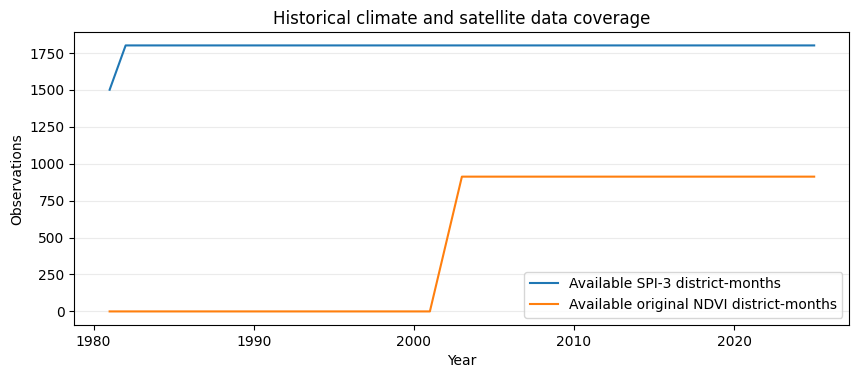

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(coverage.year, coverage.spi3_valid, label="Available SPI-3 district-months")
ax.plot(coverage.year, coverage.ndvi_valid, label="Available original NDVI district-months")
ax.set(xlabel="Year", ylabel="Observations", title="Historical climate and satellite data coverage")
ax.legend(); ax.grid(axis="y", alpha=.25)
fig.savefig(OUT / "figures" / "data_coverage_by_year.png", dpi=150, bbox_inches="tight")
plt.show(); plt.close(fig)

### Data interpretation

The dataset uses 2022 administrative district boundaries throughout the 1981–2025 period. Pre-2022 district labels therefore describe conditions assigned retrospectively to a fixed geography. The SPI-3 index was produced with a fixed 1981–2010 reference period and is not recomputed in this baseline study.